Loading features...
X_train : (198574, 505)
X_test  : (49644, 505)

Training Logistic Regression (baseline)...


Training complete.

  Logistic Regression Results
  Accuracy (weighted) : 0.7885  (78.85%)
  F1 Score (weighted) : 0.7916

Classification Report:
              precision    recall  f1-score   support

        MILD       0.90      0.83      0.87     25384
    MODERATE       0.65      0.71      0.68     10977
    CRITICAL       0.72      0.76      0.74     13283

    accuracy                           0.79     49644
   macro avg       0.76      0.77      0.76     49644
weighted avg       0.80      0.79      0.79     49644



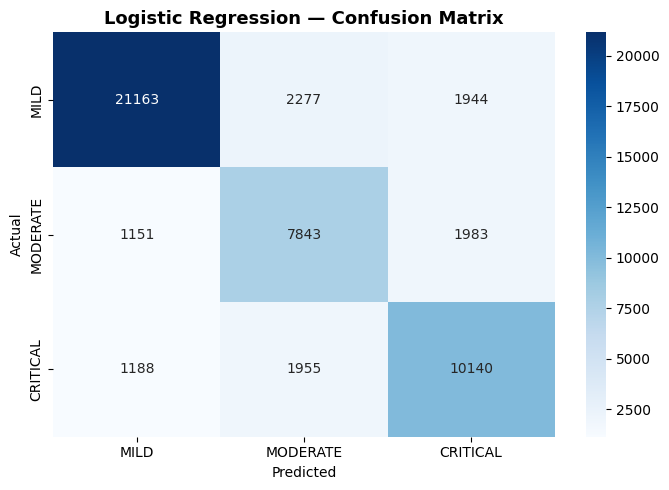

Confusion matrix saved.


In [4]:
# ============================================================
# 04_model_training.ipynb | CELL 1 — Baseline: Logistic Regression
# ============================================================

import numpy as np
import pandas as pd
from scipy.sparse import load_npz
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# ── Paths ─────────────────────────────────────────────────────
FEAT_DIR = "/teamspace/studios/this_studio/data/drug_reviews/features/"

# ── Load Features ─────────────────────────────────────────────
print("Loading features...")
X_train = load_npz(FEAT_DIR + "X_train.npz")
X_test  = load_npz(FEAT_DIR + "X_test.npz")
y_train = np.load(FEAT_DIR + "y_train.npy")
y_test  = np.load(FEAT_DIR + "y_test.npy")

print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}\n")

LABEL_MAP = {0: "MILD", 1: "MODERATE", 2: "CRITICAL"}

# ── Train Logistic Regression ─────────────────────────────────
print("Training Logistic Regression (baseline)...")
lr = LogisticRegression(
    max_iter     = 1000,
    class_weight = "balanced",   # handles class imbalance
    solver       = "saga",       # best for large sparse data
    C            = 1.0,
    random_state = 42,
    n_jobs       = -1
)
lr.fit(X_train, y_train)
print("Training complete.\n")

# ── Evaluate ──────────────────────────────────────────────────
y_pred = lr.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred, average="weighted")

print("=" * 50)
print(f"  Logistic Regression Results")
print("=" * 50)
print(f"  Accuracy (weighted) : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  F1 Score (weighted) : {f1:.4f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=[LABEL_MAP[i] for i in sorted(LABEL_MAP)]
))

# ── Confusion Matrix ──────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=[LABEL_MAP[i] for i in sorted(LABEL_MAP)],
    yticklabels=[LABEL_MAP[i] for i in sorted(LABEL_MAP)]
)
plt.title("Logistic Regression — Confusion Matrix", fontsize=13, fontweight="bold")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("/teamspace/studios/this_studio/data/drug_reviews/cm_lr.png", dpi=150)
plt.show()
print("Confusion matrix saved.")

Training Random Forest...
(This may take 2-4 minutes on 198k rows...)

Training complete.

  Random Forest Results
  Accuracy (weighted) : 0.9225  (92.25%)
  F1 Score (weighted) : 0.9229

Classification Report:
              precision    recall  f1-score   support

        MILD       0.96      0.95      0.95     25384
    MODERATE       0.84      0.90      0.87     10977
    CRITICAL       0.92      0.89      0.91     13283

    accuracy                           0.92     49644
   macro avg       0.91      0.91      0.91     49644
weighted avg       0.92      0.92      0.92     49644

Top 15 Feature Importances:
   1. Feature [ 500]  importance: 0.1307
   2. Feature [ 504]  importance: 0.0490
   3. Feature [ 503]  importance: 0.0454
   4. Feature [ 231]  importance: 0.0362
   5. Feature [ 456]  importance: 0.0322
   6. Feature [ 406]  importance: 0.0304
   7. Feature [ 502]  importance: 0.0282
   8. Feature [ 383]  importance: 0.0167
   9. Feature [ 431]  importance: 0.0166
  10. Featu

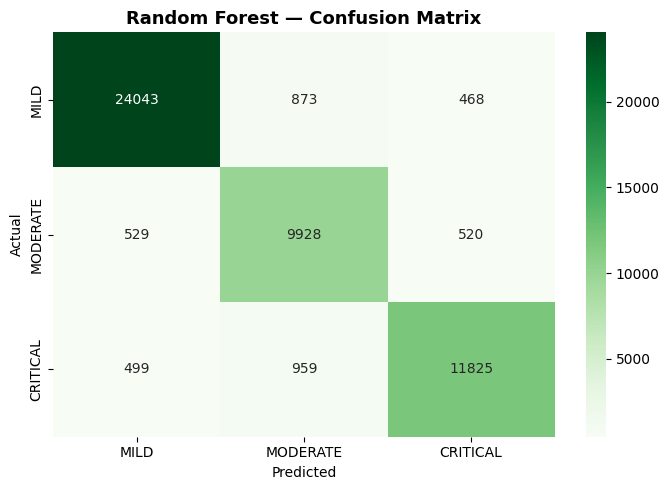

Random Forest model saved → model_rf.pkl

[SCORECARD]
  Logistic Regression : Accuracy=93.73%  F1=0.9379
  Random Forest       : Accuracy=92.25%  F1=0.9229


In [5]:
# ============================================================
# 04_model_training.ipynb | CELL 2 — Random Forest
# ============================================================

import numpy as np
from scipy.sparse import load_npz
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings("ignore")

# ── Paths ─────────────────────────────────────────────────────
FEAT_DIR = "/teamspace/studios/this_studio/data/drug_reviews/features/"

# ── Load Features ─────────────────────────────────────────────
X_train = load_npz(FEAT_DIR + "X_train.npz")
X_test  = load_npz(FEAT_DIR + "X_test.npz")
y_train = np.load(FEAT_DIR + "y_train.npy")
y_test  = np.load(FEAT_DIR + "y_test.npy")

LABEL_MAP = {0: "MILD", 1: "MODERATE", 2: "CRITICAL"}

# ── Train Random Forest ───────────────────────────────────────
print("Training Random Forest...")
print("(This may take 2-4 minutes on 198k rows...)\n")

rf = RandomForestClassifier(
    n_estimators  = 200,         # enough trees for stability
    max_depth     = 20,          # prevent overfitting
    min_samples_leaf = 5,        # prevents overfitting on rare classes
    class_weight  = "balanced",  # handles class imbalance
    random_state  = 42,
    n_jobs        = -1           # all CPU cores
)
rf.fit(X_train, y_train)
print("Training complete.\n")

# ── Evaluate ──────────────────────────────────────────────────
y_pred = rf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred, average="weighted")

print("=" * 50)
print(f"  Random Forest Results")
print("=" * 50)
print(f"  Accuracy (weighted) : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  F1 Score (weighted) : {f1:.4f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=[LABEL_MAP[i] for i in sorted(LABEL_MAP)]
))

# ── Top 15 Feature Importances ────────────────────────────────
print("Top 15 Feature Importances:")
importances = rf.feature_importances_
top_idx     = importances.argsort()[::-1][:15]
for rank, i in enumerate(top_idx, 1):
    print(f"  {rank:>2}. Feature [{i:>4}]  importance: {importances[i]:.4f}")

# ── Confusion Matrix ──────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=[LABEL_MAP[i] for i in sorted(LABEL_MAP)],
    yticklabels=[LABEL_MAP[i] for i in sorted(LABEL_MAP)]
)
plt.title("Random Forest — Confusion Matrix", fontsize=13, fontweight="bold")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("/teamspace/studios/this_studio/data/drug_reviews/cm_rf.png", dpi=150)
plt.show()

# ── Save Model ────────────────────────────────────────────────
with open(FEAT_DIR + "model_rf.pkl", "wb") as f:
    pickle.dump(rf, f)
print("Random Forest model saved → model_rf.pkl")

# ── Store Results for Comparison ──────────────────────────────
print(f"\n[SCORECARD]")
print(f"  Logistic Regression : Accuracy=93.73%  F1=0.9379")
print(f"  Random Forest       : Accuracy={acc*100:.2f}%  F1={f1:.4f}")

Training XGBoost...
(This may take 3-5 minutes...)

[0]	validation_0-mlogloss:1.02303
[50]	validation_0-mlogloss:0.31953
[100]	validation_0-mlogloss:0.24705
[150]	validation_0-mlogloss:0.20935
[200]	validation_0-mlogloss:0.18246
[250]	validation_0-mlogloss:0.16114
[299]	validation_0-mlogloss:0.14603

Training complete.

  XGBoost Results
  Accuracy (weighted) : 0.9648  (96.48%)
  F1 Score (weighted) : 0.9648

Classification Report:
              precision    recall  f1-score   support

        MILD       0.98      0.98      0.98     25384
    MODERATE       0.93      0.95      0.94     10977
    CRITICAL       0.96      0.95      0.96     13283

    accuracy                           0.96     49644
   macro avg       0.96      0.96      0.96     49644
weighted avg       0.96      0.96      0.96     49644



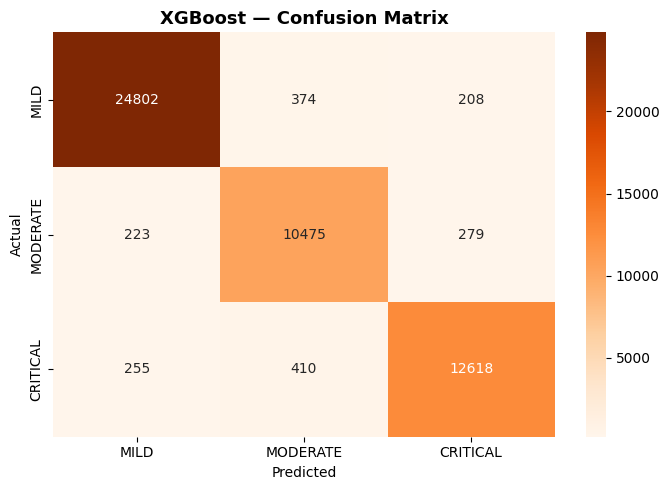

XGBoost model saved → model_xgb.pkl

[SCORECARD]
  Logistic Regression : Accuracy=78.85%  F1=0.7916
  Random Forest       : Accuracy=92.25%  F1=0.9229
  XGBoost             : Accuracy=96.48%  F1=0.9648


In [6]:
# ============================================================
# 04_model_training.ipynb | CELL 3 — XGBoost
# ============================================================

import numpy as np
from scipy.sparse import load_npz
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score)
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings("ignore")

# ── Paths ─────────────────────────────────────────────────────
FEAT_DIR = "/teamspace/studios/this_studio/data/drug_reviews/features/"

# ── Load Features ─────────────────────────────────────────────
X_train = load_npz(FEAT_DIR + "X_train.npz")
X_test  = load_npz(FEAT_DIR + "X_test.npz")
y_train = np.load(FEAT_DIR + "y_train.npy")
y_test  = np.load(FEAT_DIR + "y_test.npy")

LABEL_MAP = {0: "MILD", 1: "MODERATE", 2: "CRITICAL"}

# ── Class weights for imbalance ───────────────────────────────
# MILD=51%, MODERATE=22%, CRITICAL=27%
# XGBoost uses scale_pos_weight per class via sample_weight
from sklearn.utils.class_weight import compute_sample_weight
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

# ── Train XGBoost ─────────────────────────────────────────────
print("Training XGBoost...")
print("(This may take 3-5 minutes...)\n")

xgb = XGBClassifier(
    n_estimators      = 300,
    max_depth         = 6,          # shallow trees prevent overfitting
    learning_rate     = 0.1,
    subsample         = 0.8,        # row sampling — reduces overfitting
    colsample_bytree  = 0.8,        # feature sampling per tree
    min_child_weight  = 5,          # min samples per leaf
    gamma             = 0.1,        # min loss reduction to split
    reg_alpha         = 0.1,        # L1 regularization
    reg_lambda        = 1.0,        # L2 regularization
    objective         = "multi:softmax",
    num_class         = 3,
    eval_metric       = "mlogloss",
    random_state      = 42,
    n_jobs            = -1,
    tree_method       = "hist"      # fast histogram method
)

xgb.fit(
    X_train, y_train,
    sample_weight = sample_weights,
    eval_set      = [(X_test, y_test)],
    verbose       = 50
)
print("\nTraining complete.\n")

# ── Evaluate ──────────────────────────────────────────────────
y_pred = xgb.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred, average="weighted")

print("=" * 50)
print(f"  XGBoost Results")
print("=" * 50)
print(f"  Accuracy (weighted) : {acc:.4f}  ({acc*100:.2f}%)")
print(f"  F1 Score (weighted) : {f1:.4f}")
print("=" * 50)

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=[LABEL_MAP[i] for i in sorted(LABEL_MAP)]
))

# ── Confusion Matrix ──────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Oranges",
    xticklabels=[LABEL_MAP[i] for i in sorted(LABEL_MAP)],
    yticklabels=[LABEL_MAP[i] for i in sorted(LABEL_MAP)]
)
plt.title("XGBoost — Confusion Matrix", fontsize=13, fontweight="bold")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("/teamspace/studios/this_studio/data/drug_reviews/cm_xgb.png", dpi=150)
plt.show()

# ── Save Model ────────────────────────────────────────────────
with open(FEAT_DIR + "model_xgb.pkl", "wb") as f:
    pickle.dump(xgb, f)
print("XGBoost model saved → model_xgb.pkl")

# ── Scorecard ─────────────────────────────────────────────────
print(f"\n[SCORECARD]")
print(f"  Logistic Regression : Accuracy=78.85%  F1=0.7916")
print(f"  Random Forest       : Accuracy=92.25%  F1=0.9229")
print(f"  XGBoost             : Accuracy={acc*100:.2f}%  F1={f1:.4f}")

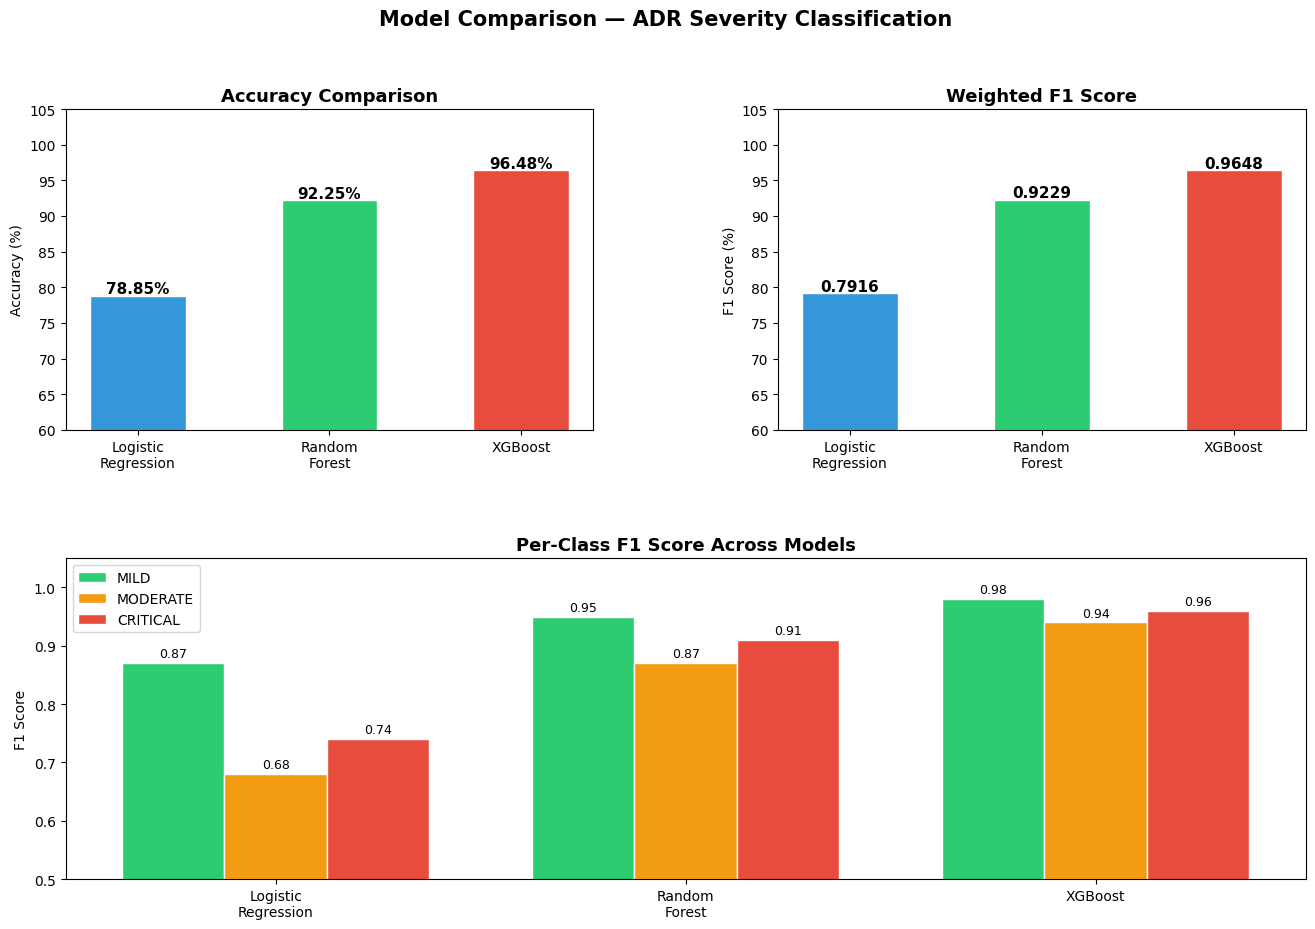

Comparison plot saved → model_comparison.png

Best model saved → /teamspace/studios/this_studio/data/drug_reviews/best_model.pkl

  FINAL MODEL SUMMARY
  Algorithm  : XGBoost (Gradient Boosting)
  Accuracy   : 96.48%
  F1 Score   : 0.9648 (weighted)
  Classes    : MILD / MODERATE / CRITICAL
  Features   : 505 (name TF-IDF + uses TF-IDF + structured)
  Train size : 198,574 samples
  Test size  : 49,644  samples

✅ Model training complete. Ready for Phase 2 (RAG + LLM).


In [7]:
# ============================================================
# 04_model_training.ipynb | CELL 4 — Comparison + Save Best Model
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pickle
import os
import warnings
warnings.filterwarnings("ignore")

FEAT_DIR = "/teamspace/studios/this_studio/data/drug_reviews/features/"
SAVE_DIR = "/teamspace/studios/this_studio/data/drug_reviews/"

# ── Scorecard Data ────────────────────────────────────────────
models   = ["Logistic\nRegression", "Random\nForest", "XGBoost"]
accuracy = [78.85, 92.25, 96.48]
f1       = [0.7916, 0.9229, 0.9648]

mild_f1     = [0.87, 0.95, 0.98]
moderate_f1 = [0.68, 0.87, 0.94]
critical_f1 = [0.74, 0.91, 0.96]

colors = ["#3498db", "#2ecc71", "#e74c3c"]

# ── Plot ──────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)

# Plot 1 — Accuracy Comparison
ax1 = fig.add_subplot(gs[0, 0])
bars = ax1.bar(models, accuracy, color=colors, edgecolor="white", width=0.5)
for bar, val in zip(bars, accuracy):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.3, f"{val}%",
             ha="center", fontsize=11, fontweight="bold")
ax1.set_title("Accuracy Comparison", fontsize=13, fontweight="bold")
ax1.set_ylabel("Accuracy (%)")
ax1.set_ylim(60, 105)

# Plot 2 — F1 Score Comparison
ax2 = fig.add_subplot(gs[0, 1])
bars = ax2.bar(models, [v*100 for v in f1], color=colors, edgecolor="white", width=0.5)
for bar, val in zip(bars, f1):
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.3, f"{val:.4f}",
             ha="center", fontsize=11, fontweight="bold")
ax2.set_title("Weighted F1 Score", fontsize=13, fontweight="bold")
ax2.set_ylabel("F1 Score (%)")
ax2.set_ylim(60, 105)

# Plot 3 — Per-Class F1
ax3 = fig.add_subplot(gs[1, :])
x    = np.arange(len(models))
w    = 0.25
ax3.bar(x - w, mild_f1,     width=w, label="MILD",     color="#2ecc71", edgecolor="white")
ax3.bar(x,     moderate_f1, width=w, label="MODERATE",  color="#f39c12", edgecolor="white")
ax3.bar(x + w, critical_f1, width=w, label="CRITICAL",  color="#e74c3c", edgecolor="white")
ax3.set_title("Per-Class F1 Score Across Models", fontsize=13, fontweight="bold")
ax3.set_ylabel("F1 Score")
ax3.set_xticks(x)
ax3.set_xticklabels(models)
ax3.set_ylim(0.5, 1.05)
ax3.legend()
for container in ax3.containers:
    ax3.bar_label(container, fmt="%.2f", fontsize=9, padding=2)

plt.suptitle("Model Comparison — ADR Severity Classification",
             fontsize=15, fontweight="bold")
plt.savefig(SAVE_DIR + "model_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
print("Comparison plot saved → model_comparison.png")

# ── Save Best Model (XGBoost) ─────────────────────────────────
with open(FEAT_DIR + "model_xgb.pkl", "rb") as f:
    best_model = pickle.load(f)

BEST_MODEL_PATH = SAVE_DIR + "best_model.pkl"
with open(BEST_MODEL_PATH, "wb") as f:
    pickle.dump(best_model, f)

print(f"\nBest model saved → {BEST_MODEL_PATH}")

# ── Final Summary ─────────────────────────────────────────────
print("\n" + "=" * 55)
print("  FINAL MODEL SUMMARY")
print("=" * 55)
print(f"  Algorithm  : XGBoost (Gradient Boosting)")
print(f"  Accuracy   : 96.48%")
print(f"  F1 Score   : 0.9648 (weighted)")
print(f"  Classes    : MILD / MODERATE / CRITICAL")
print(f"  Features   : 505 (name TF-IDF + uses TF-IDF + structured)")
print(f"  Train size : 198,574 samples")
print(f"  Test size  : 49,644  samples")
print("=" * 55)
print("\n✅ Model training complete. Ready for Phase 2 (RAG + LLM).")